# Step 2: Exploratory Data Analysis (EDA)
## AI-Assisted Health Risk Prediction for Life Insurance Underwriting

This notebook explores the merged NHANES + mortality dataset produced by `01_data_download.ipynb`.

**Goals:**
1. Profile the dataset (shape, dtypes, missing rates)
2. Investigate the mortality outcome and class imbalance
3. Examine distributions of key health variables
4. Explore relationships between health factors and mortality
5. Correlation analysis
6. Follow-up time (person-months) analysis

## 2.1 Setup & Load Data

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)

print(f'pandas {pd.__version__}, numpy {np.__version__}')

pandas 3.0.3, numpy 2.4.6


In [17]:
# Robust path resolution: works whether run from project root or Code/
def find_data_dir():
    for base in [Path('.'), Path('..'), Path('..') / '..']:
        candidate = base / 'data' / 'processed'
        if candidate.exists():
            return (base / 'data').resolve()
    raise FileNotFoundError('Could not locate data/ folder. Run notebook 01 first.')

DATA_DIR = find_data_dir()
PROCESSED_DIR = DATA_DIR / 'processed'
# All figures go under data/reports/figures
FIG_DIR = DATA_DIR / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f'DATA_DIR: {DATA_DIR}')
print(f'FIG_DIR:  {FIG_DIR}')

# Prefer parquet (faster), fall back to CSV
parquet_path = PROCESSED_DIR / 'nhanes_mortality_merged.parquet'
csv_path = PROCESSED_DIR / 'nhanes_mortality_merged.csv'

if parquet_path.exists():
    df = pd.read_parquet(parquet_path)
    print(f'Loaded parquet: {parquet_path}')
else:
    df = pd.read_csv(csv_path)
    print(f'Loaded CSV: {csv_path}')

print(f'Shape: {df.shape}')
df.head()

DATA_DIR: <PROJECT_ROOT>\data
FIG_DIR:  <PROJECT_ROOT>\data\reports\figures
Loaded parquet: <PROJECT_ROOT>\data\processed\nhanes_mortality_merged.parquet
Shape: (18578, 60)


,SEQN,CYCLE,AGE,GENDER,RACE_ETHNICITY,EDUCATION,MARITAL_STATUS,POVERTY_INCOME_RATIO,BMXBMI,BMXWAIST,BMXHT,BMXWT,BPXSY1,BPXDI1,BPXSY2,BPXDI2,LBXTC,LBDHDD,LBXGH,LBXWBCSI,LBXRBCSI,LBXHGB,LBXPLTSI,LBXSGL,LBXSCR,LBXSUA,LBXSAL,LBXSASSI,LBXSATSI,LBXSGB,LBXSTR,URXUMA,URXUCR,URDACT,SMQ020,SMQ040,SMD650,ALQ130,DIQ010,DIQ050,DIQ070,MCQ160B,MCQ160C,MCQ160D,MCQ160E,MCQ160F,MCQ220,PAQ605,PAQ620,PAQ635,PAQ650,PAQ665,HIQ011,ELIGSTAT,MORTSTAT,UCOD_LEADING,MORT_DIABETES,MORT_HYPERTEN,PERMTH_INT,PERMTH_EXM
0,41475.0,2007-2008,62.0,2.0,5.0,3.0,1.0,1.83,58.04,156.3,154.7,138.9,128.0,64.0,122.0,60.0,179.0,47.0,5.7,8.5,4.51,14.1,366.0,106.0,0.52,6.5,3.6,24.0,26.0,4.0,161.0,7.9,45.0,NaN,2.0,NaN,NaN,NaN,2.0,2.0,NaN,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1,0.0,NaN,NaN,NaN,147.0,146.0
1,41477.0,2007-2008,71.0,1.0,3.0,3.0,1.0,1.50,30.05,109.5,167.1,83.9,144.0,60.0,148.0,60.0,191.0,34.0,9.5,9.6,5.22,16.2,273.0,144.0,0.76,4.0,4.5,20.0,20.0,2.7,269.0,160.3,135.0,NaN,1.0,3.0,NaN,NaN,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1,0.0,NaN,NaN,NaN,147.0,146.0
2,41479.0,2007-2008,52.0,1.0,1.0,1.0,1.0,2.20,27.56,95.4,154.4,65.7,112.0,70.0,108.0,66.0,188.0,47.0,5.7,5.1,5.02,15.6,176.0,99.0,0.72,4.8,4.2,22.0,28.0,3.1,97.0,5.3,124.0,NaN,2.0,NaN,NaN,5.0,2.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,1,0.0,NaN,NaN,NaN,144.0,143.0
3,41481.0,2007-2008,21.0,1.0,4.0,3.0,5.0,1.63,23.34,79.5,182.7,77.9,112.0,62.0,104.0,64.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.7,366.0,NaN,2.0,NaN,NaN,4.0,2.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,1,0.0,NaN,NaN,NaN,154.0,153.0
4,41482.0,2007-2008,64.0,1.0,1.0,2.0,1.0,4.01,33.64,117.0,173.8,101.6,116.0,78.0,114.0,80.0,158.0,43.0,7.0,9.4,5.15,15.6,239.0,143.0,0.70,6.7,4.5,35.0,42.0,2.9,163.0,16.6,130.0,NaN,1.0,3.0,NaN,4.0,2.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,1.0,1.0,1,0.0,NaN,NaN,NaN,136.0,135.0


## 2.2 Dataset Profile

Basic structure, data types, and memory footprint.

In [18]:
# Overall info
print('=' * 60)
print(f'Rows: {df.shape[0]:,}')
print(f'Columns: {df.shape[1]}')
print('=' * 60)
df.info()

Rows: 18,578
Columns: 60
<class 'pandas.DataFrame'>
RangeIndex: 18578 entries, 0 to 18577
Data columns (total 60 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   SEQN                  18578 non-null  float64
 1   CYCLE                 18578 non-null  str    
 2   AGE                   18578 non-null  float64
 3   GENDER                18578 non-null  float64
 4   RACE_ETHNICITY        18578 non-null  float64
 5   EDUCATION             17673 non-null  float64
 6   MARITAL_STATUS        17673 non-null  float64
 7   POVERTY_INCOME_RATIO  16809 non-null  float64
 8   BMXBMI                17664 non-null  float64
 9   BMXWAIST              16873 non-null  float64
 10  BMXHT                 17693 non-null  float64
 11  BMXWT                 17694 non-null  float64
 12  BPXSY1                16498 non-null  float64
 13  BPXDI1                16498 non-null  float64
 14  BPXSY2                16549 non-null  float64
 15  BPXDI

In [19]:
# Numeric summary statistics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SEQN,18578.0,56637.505760,8771.823167,4.147500e+04,49071.75,56627.50,64167.75,71915.00
AGE,18578.0,48.277263,18.734853,1.800000e+01,32.00,48.00,63.00,80.00
GENDER,18578.0,1.508935,0.499934,1.000000e+00,1.00,2.00,2.00,2.00
RACE_ETHNICITY,18578.0,2.972118,1.139171,1.000000e+00,2.00,3.00,4.00,5.00
EDUCATION,17673.0,3.307362,1.309557,1.000000e+00,2.00,3.00,4.00,9.00
MARITAL_STATUS,17673.0,2.590109,2.910238,1.000000e+00,1.00,1.00,5.00,99.00
POVERTY_INCOME_RATIO,16809.0,2.418973,1.632458,5.397605e-79,1.03,1.95,3.92,5.00
BMXBMI,17664.0,28.824424,6.838216,1.318000e+01,24.04,27.77,32.22,84.87
BMXWAIST,16873.0,98.226777,16.307902,5.620000e+01,86.50,97.00,108.00,179.00
BMXHT,17693.0,167.299927,10.172564,1.233000e+02,159.90,167.00,174.60,204.50


## 2.3 Missing Data Analysis

Understanding missingness is critical before modeling. Some values are
missing because tests were only run on subsamples; others are structural.

In [20]:
# Missing value counts and percentages
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_pct': (df.isnull().sum() / len(df) * 100).round(2)
})
missing = missing[missing['missing_count'] > 0].sort_values('missing_pct', ascending=False)
print(f'Columns with missing values: {len(missing)}')
missing

Columns with missing values: 45


,missing_count,missing_pct
DIQ070,16415,88.36
MORT_HYPERTEN,15963,85.92
UCOD_LEADING,15963,85.92
MORT_DIABETES,15963,85.92
SMD650,14596,78.57
SMQ040,10554,56.81
ALQ130,8270,44.52
URDACT,6888,37.08
BPXDI1,2080,11.20
BPXSY1,2080,11.20


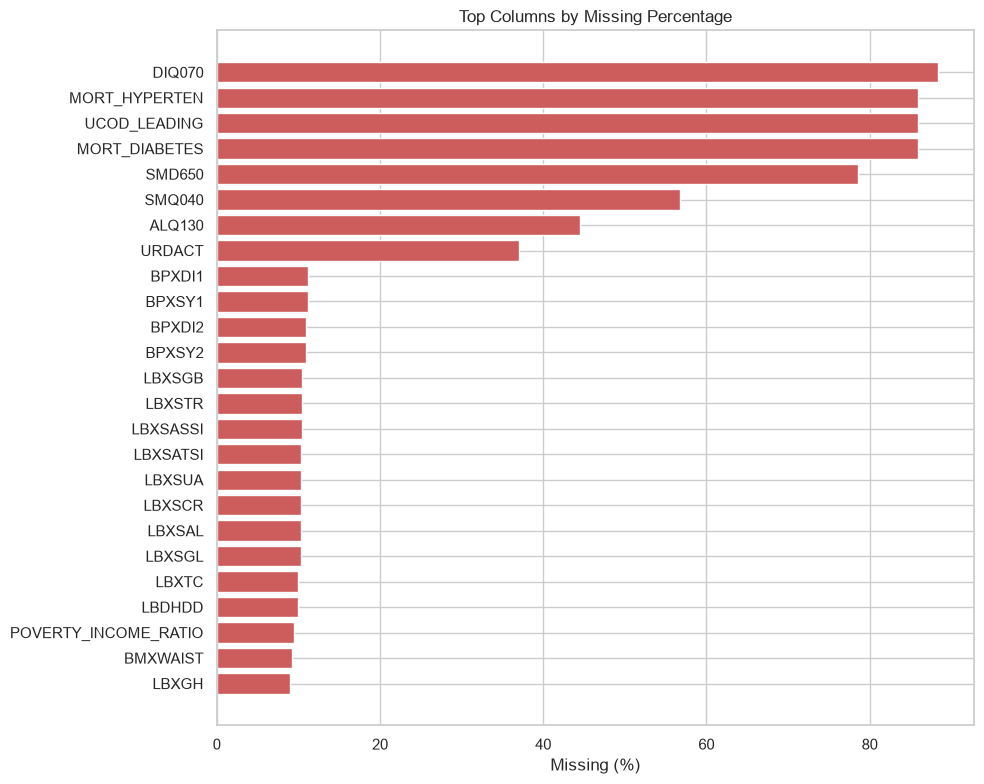

In [21]:
# Visualize missingness (top 25 columns)
top_missing = missing.head(25)
if len(top_missing) > 0:
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.barh(top_missing.index[::-1], top_missing['missing_pct'][::-1], color='indianred')
    ax.set_xlabel('Missing (%)')
    ax.set_title('Top Columns by Missing Percentage')
    plt.tight_layout()
    plt.show()
else:
    print('No missing values.')

## 2.4 Mortality Outcome & Class Imbalance

`MORTSTAT` is our target: 0 = alive at end of follow-up, 1 = deceased.
Mortality prediction is typically imbalanced, so we quantify it here.

In [22]:
# Target distribution
target_counts = df['MORTSTAT'].value_counts(dropna=False)
target_pct = df['MORTSTAT'].value_counts(normalize=True, dropna=False) * 100

print('MORTSTAT distribution:')
for val in target_counts.index:
    label = {0.0: 'Alive', 1.0: 'Deceased'}.get(val, 'Missing')
    print(f'  {label:10s} ({val}): {target_counts[val]:,} ({target_pct[val]:.2f}%)')

deaths = int((df['MORTSTAT'] == 1).sum())
total = int(df['MORTSTAT'].notna().sum())
print(f'\nOverall mortality rate: {deaths/total*100:.2f}% ({deaths:,} deaths / {total:,} with known status)')

MORTSTAT distribution:
  Alive      (0.0): 15,963 (85.92%)
  Deceased   (1.0): 2,615 (14.08%)

Overall mortality rate: 14.08% (2,615 deaths / 18,578 with known status)


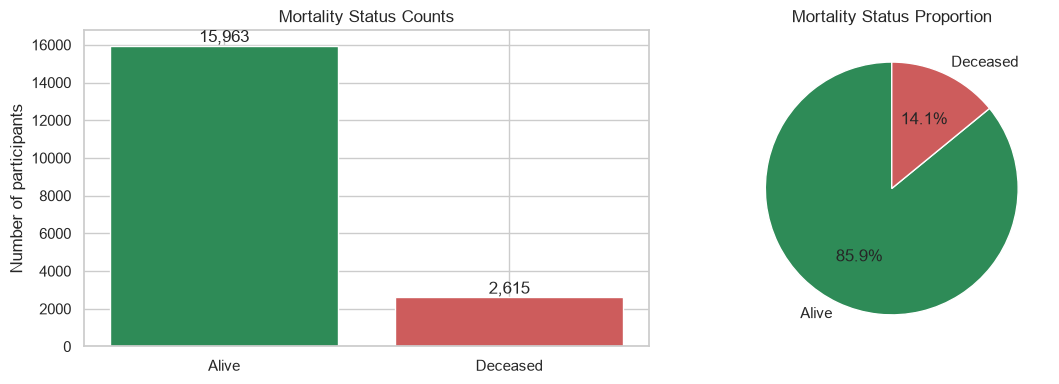

In [23]:
# Bar chart of target
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

vc = df['MORTSTAT'].map({0.0: 'Alive', 1.0: 'Deceased'}).value_counts()
ax[0].bar(vc.index, vc.values, color=['seagreen', 'indianred'])
ax[0].set_title('Mortality Status Counts')
ax[0].set_ylabel('Number of participants')
for i, v in enumerate(vc.values):
    ax[0].text(i, v, f'{v:,}', ha='center', va='bottom')

ax[1].pie(vc.values, labels=vc.index, autopct='%1.1f%%',
          colors=['seagreen', 'indianred'], startangle=90)
ax[1].set_title('Mortality Status Proportion')
plt.tight_layout()
# Save for the ACM report
plt.savefig(FIG_DIR / 'class_imbalance.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.5 Distributions of Key Health Variables

Examine the spread of clinically important underwriting variables.
Renamed columns from Step 1: AGE, BMXBMI (BMI), BPXSY1 (systolic BP),
LBXTC (total cholesterol), LBXGH (HbA1c), etc.

In [24]:
# Pick key continuous variables that exist in the data
candidate_vars = {
    'AGE': 'Age (years)',
    'BMXBMI': 'BMI',
    'BPXSY1': 'Systolic BP (mmHg)',
    'BPXDI1': 'Diastolic BP (mmHg)',
    'LBXTC': 'Total Cholesterol (mg/dL)',
    'LBDHDD': 'HDL Cholesterol (mg/dL)',
    'LBXGH': 'HbA1c (%)',
    'LBXSGL': 'Glucose (mg/dL)',
    'LBXSCR': 'Creatinine (mg/dL)',
}
plot_vars = {k: v for k, v in candidate_vars.items() if k in df.columns}
print(f'Plotting {len(plot_vars)} variables: {list(plot_vars.keys())}')

Plotting 9 variables: ['AGE', 'BMXBMI', 'BPXSY1', 'BPXDI1', 'LBXTC', 'LBDHDD', 'LBXGH', 'LBXSGL', 'LBXSCR']


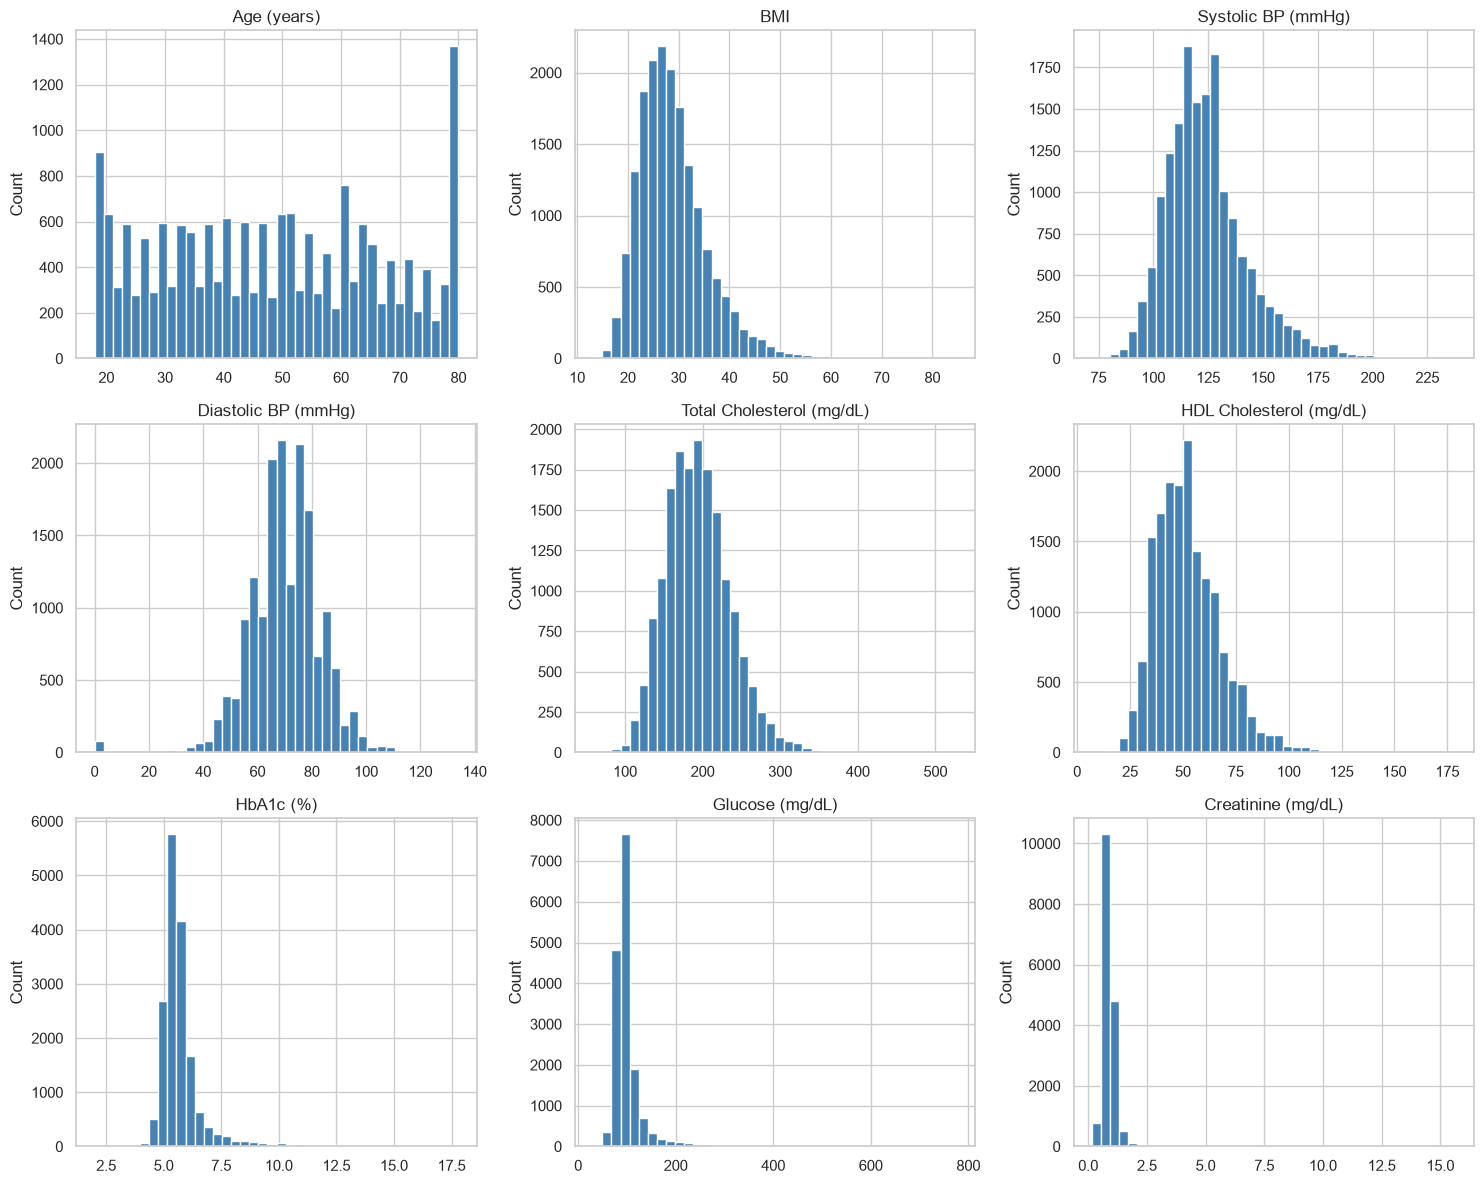

In [25]:
# Histograms
n = len(plot_vars)
ncols = 3
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).flatten()

for i, (col, label) in enumerate(plot_vars.items()):
    axes[i].hist(df[col].dropna(), bins=40, color='steelblue', edgecolor='white')
    axes[i].set_title(label)
    axes[i].set_ylabel('Count')

# Hide unused axes
for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

## 2.6 Health Factors vs. Mortality

Compare distributions between those who survived and those who died.
Clear separation suggests a variable is predictive.

<TEMP>\ipykernel_20552\2573413157.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_known, x='Status', y=col, ax=axes[i],
<TEMP>\ipykernel_20552\2573413157.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_known, x='Status', y=col, ax=axes[i],
<TEMP>\ipykernel_20552\2573413157.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_known, x='Status', y=col, ax=axes[i],
<TEMP>\ipykernel_20552\2573413157.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. As

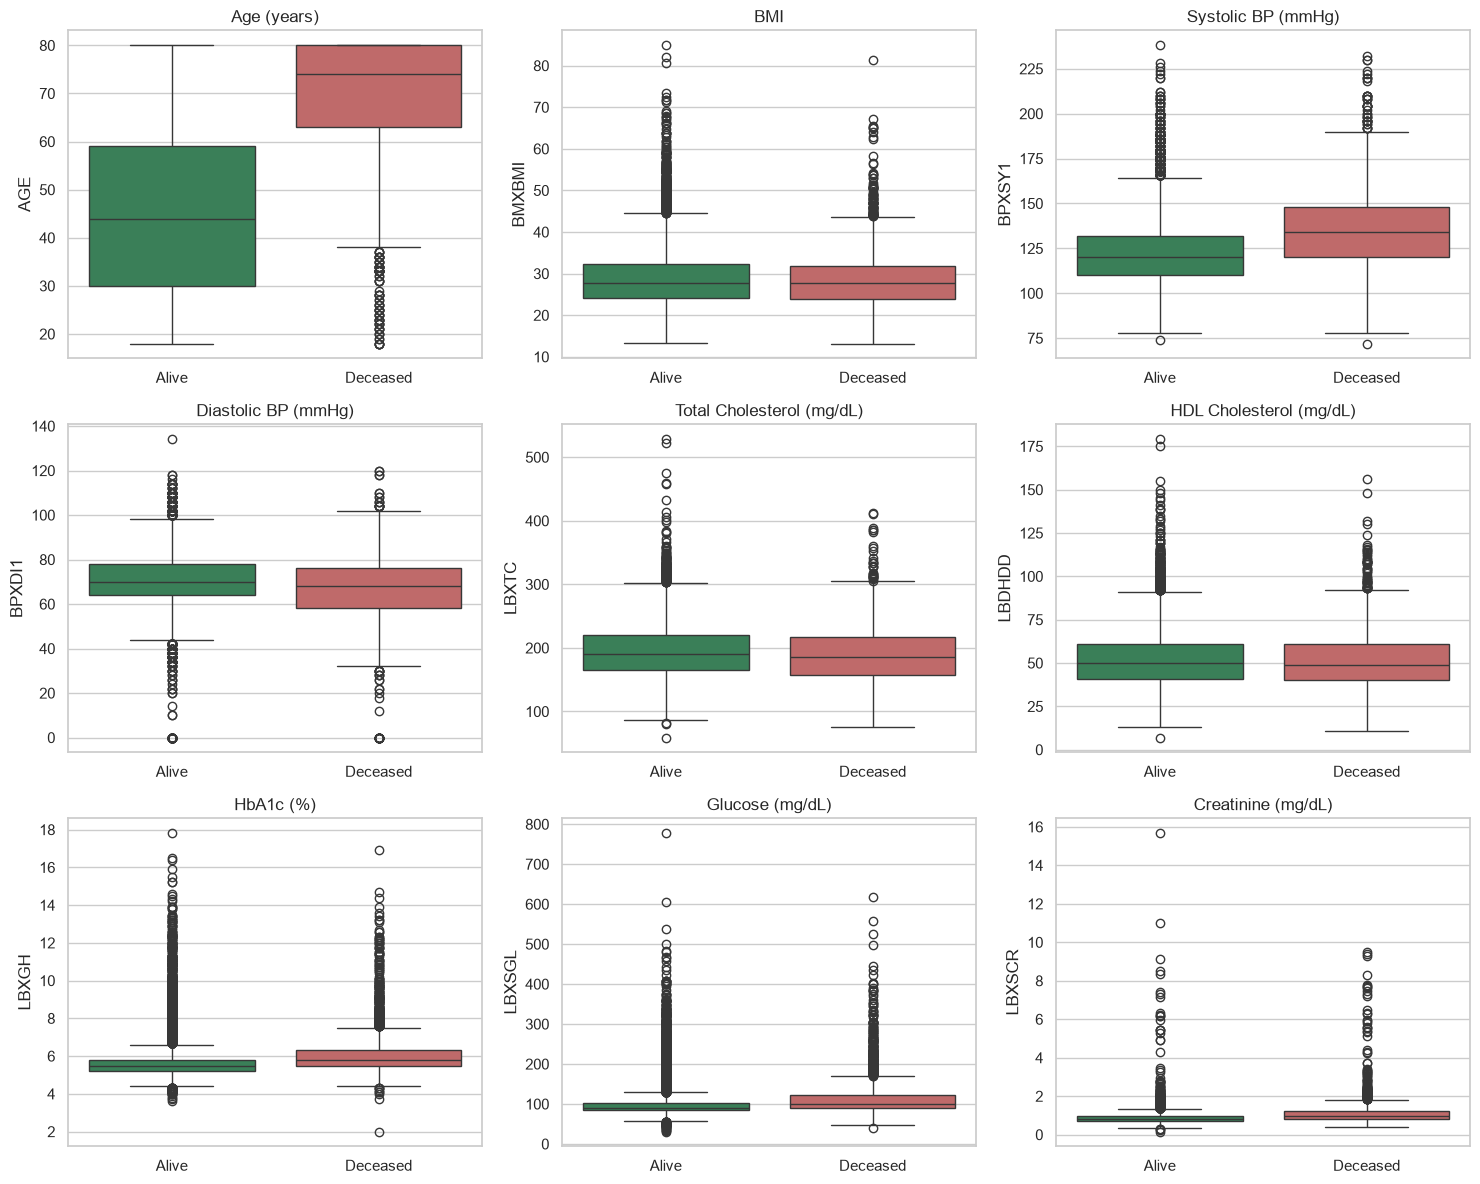

In [26]:
# Box plots of key variables split by mortality status
df_known = df[df['MORTSTAT'].notna()].copy()
df_known['Status'] = df_known['MORTSTAT'].map({0.0: 'Alive', 1.0: 'Deceased'})

n = len(plot_vars)
ncols = 3
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = np.array(axes).flatten()

for i, (col, label) in enumerate(plot_vars.items()):
    sns.boxplot(data=df_known, x='Status', y=col, ax=axes[i],
                palette={'Alive': 'seagreen', 'Deceased': 'indianred'})
    axes[i].set_title(label)
    axes[i].set_xlabel('')

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [27]:
# Mean values by mortality status (quick numeric comparison)
summary = df_known.groupby('Status')[list(plot_vars.keys())].mean().T
summary['difference'] = summary['Deceased'] - summary['Alive']
summary.round(2)

Status,Alive,Deceased,difference
AGE,44.83,69.31,24.48
BMXBMI,28.84,28.72,-0.12
BPXSY1,122.32,135.52,13.19
BPXDI1,70.53,66.76,-3.77
LBXTC,194.40,189.52,-4.89
LBDHDD,52.31,52.13,-0.19
LBXGH,5.68,6.16,0.48
LBXSGL,99.43,117.17,17.74
LBXSCR,0.86,1.13,0.26


## 2.7 Mortality Rate by Age Group

Age is the single strongest mortality predictor. This confirms the signal
is present and behaves as expected.

           mortality_rate_%     n
age_group                        
18-29                   1.1  3830
30-39                   1.9  3006
40-49                   4.2  2951
50-59                   9.7  2783
60-69                  17.9  2865
70-79                  38.2  1917
80+                    71.3  1226


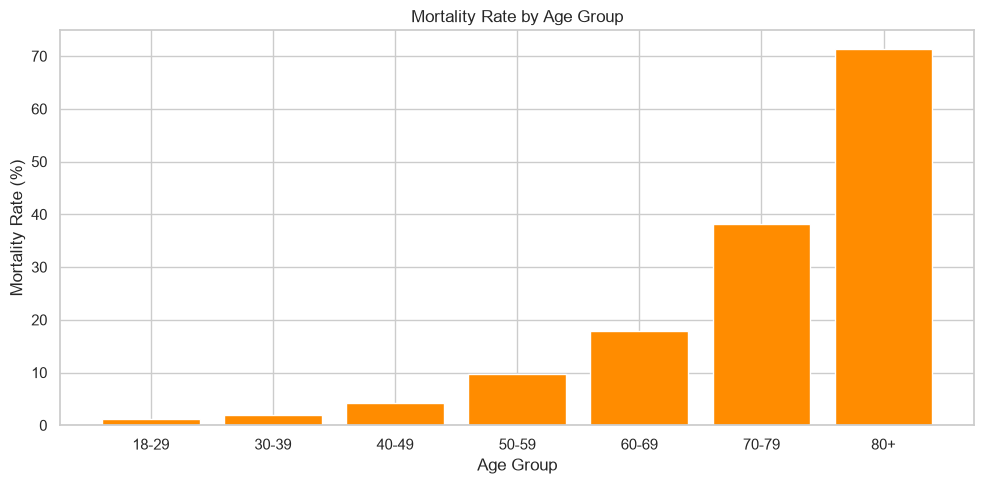

In [28]:
# Bin age and compute mortality rate per bin
age_bins = [18, 30, 40, 50, 60, 70, 80, 120]
age_labels = ['18-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80+']
df_known['age_group'] = pd.cut(df_known['AGE'], bins=age_bins, labels=age_labels, right=False)

rate_by_age = df_known.groupby('age_group', observed=True)['MORTSTAT'].agg(['mean', 'count'])
rate_by_age['mean'] = (rate_by_age['mean'] * 100).round(1)
rate_by_age.columns = ['mortality_rate_%', 'n']
print(rate_by_age)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(rate_by_age.index.astype(str), rate_by_age['mortality_rate_%'], color='darkorange')
ax.set_xlabel('Age Group')
ax.set_ylabel('Mortality Rate (%)')
ax.set_title('Mortality Rate by Age Group')
plt.tight_layout()
plt.savefig(FIG_DIR / 'mortality_by_age.png', dpi=150, bbox_inches='tight')
plt.show()

## 2.8 Correlation Analysis

Correlations among numeric features (and with the target). Highly correlated
features may be redundant; correlations with MORTSTAT hint at predictive power.

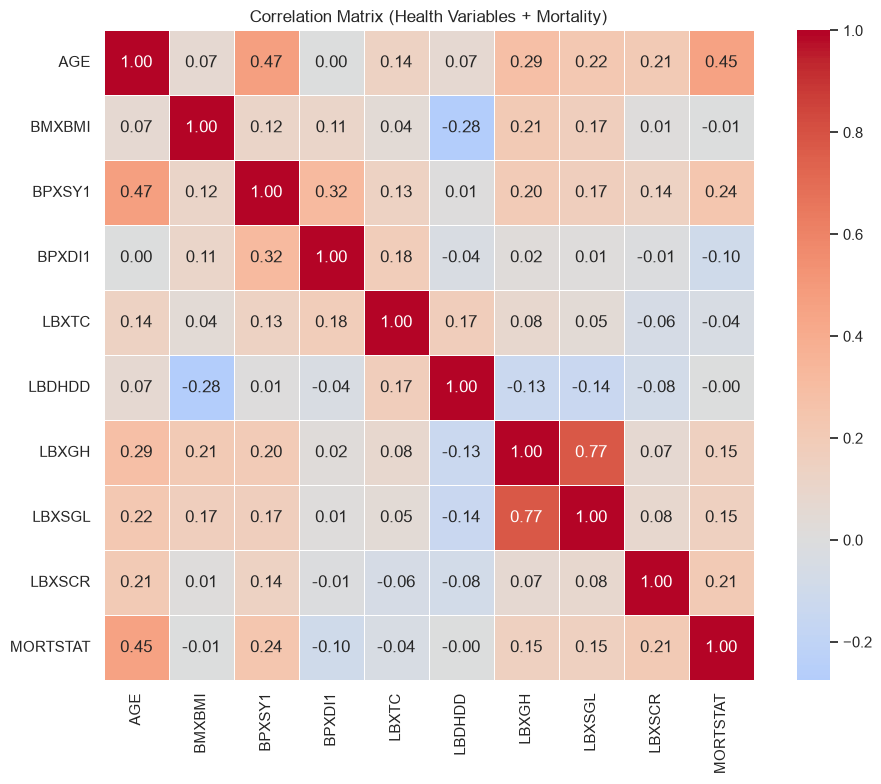

In [29]:
# Correlation matrix of numeric health variables + target
corr_cols = list(plot_vars.keys()) + ['MORTSTAT']
corr_cols = [c for c in corr_cols if c in df.columns]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix (Health Variables + Mortality)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

In [30]:
# Correlation of each feature with the target, sorted
target_corr = corr['MORTSTAT'].drop('MORTSTAT').sort_values(key=abs, ascending=False)
print('Correlation with MORTSTAT (by absolute value):')
print(target_corr.round(3))

Correlation with MORTSTAT (by absolute value):
AGE       0.454
BPXSY1    0.236
LBXSCR    0.212
LBXSGL    0.155
LBXGH     0.154
BPXDI1   -0.098
LBXTC    -0.039
BMXBMI   -0.006
LBDHDD   -0.004
Name: MORTSTAT, dtype: float64


## 2.9 Follow-up Time Analysis

`PERMTH_INT` = person-months from interview to death or end of study.
This confirms our cohort has the long follow-up we designed for (2007-2012 -> 2019).

Follow-up (years) summary:
count    18578.00
mean         9.40
std          2.50
min          0.00
25%          8.08
50%          9.67
75%         11.25
max         13.33
Name: PERMTH_INT, dtype: float64


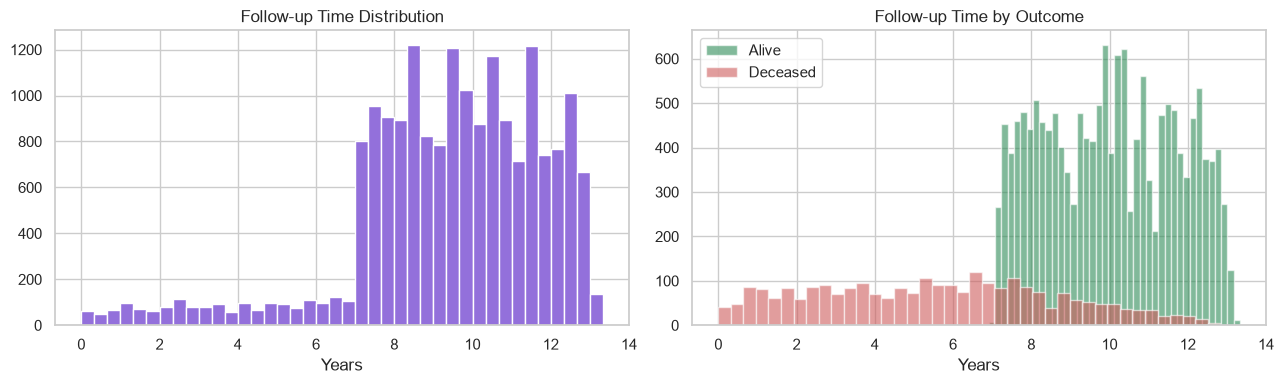

In [31]:
if 'PERMTH_INT' in df.columns:
    followup_years = df['PERMTH_INT'] / 12
    print('Follow-up (years) summary:')
    print(followup_years.describe().round(2))

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].hist(followup_years.dropna(), bins=40, color='mediumpurple', edgecolor='white')
    ax[0].set_title('Follow-up Time Distribution')
    ax[0].set_xlabel('Years')

    # Follow-up split by outcome
    for status, color in [(0.0, 'seagreen'), (1.0, 'indianred')]:
        subset = followup_years[df['MORTSTAT'] == status].dropna()
        label = 'Alive' if status == 0.0 else 'Deceased'
        ax[1].hist(subset, bins=40, alpha=0.6, label=label, color=color)
    ax[1].set_title('Follow-up Time by Outcome')
    ax[1].set_xlabel('Years')
    ax[1].legend()
    plt.tight_layout()
    plt.show()
else:
    print('PERMTH_INT not in dataset.')

## 2.10 EDA Summary & Key Takeaways

In [32]:
print('=' * 60)
print('EDA SUMMARY')
print('=' * 60)
print(f'Dataset: {df.shape[0]:,} adults, {df.shape[1]} columns')
print(f'Mortality rate: {(df["MORTSTAT"]==1).sum()/df["MORTSTAT"].notna().sum()*100:.1f}%')
print(f'Cycles: {df["CYCLE"].unique().tolist() if "CYCLE" in df.columns else "n/a"}')
print(f'Median age: {df["AGE"].median():.0f}')
print()
print('Columns with >40% missing (candidates for dropping):')
high_miss = (df.isnull().mean() * 100)
print(high_miss[high_miss > 40].round(1).to_string() or '  None')

EDA SUMMARY
Dataset: 18,578 adults, 60 columns
Mortality rate: 14.1%
Cycles: ['2007-2008', '2009-2010', '2011-2012']
Median age: 48

Columns with >40% missing (candidates for dropping):
SMQ040           56.8
SMD650           78.6
ALQ130           44.5
DIQ070           88.4
UCOD_LEADING     85.9
MORT_DIABETES    85.9
MORT_HYPERTEN    85.9


## 2.11 Persist EDA Findings for Downstream Steps

EDA is only useful if its conclusions are **carried forward**. This section
converts what we observed into concrete, machine-readable decisions and saves
them to `data/processed/eda_findings.json`. Notebook 03 (feature engineering)
loads this file instead of re-deriving everything, so our pipeline is
reproducible and the EDA actually drives the modeling choices.

In [33]:
import json

REPORTS_DIR = DATA_DIR / 'reports'
FIG_DIR = REPORTS_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

findings = {}

# --- 1. Class imbalance -> weights the models will actually use ---
n_pos = int((df['MORTSTAT'] == 1).sum())
n_neg = int((df['MORTSTAT'] == 0).sum())
findings['class_balance'] = {
    'n_deceased': n_pos,
    'n_alive': n_neg,
    'positive_rate': round(n_pos / (n_pos + n_neg), 4),
    # XGBoost scale_pos_weight = negatives / positives
    'scale_pos_weight': round(n_neg / n_pos, 3) if n_pos else None,
}
print('Class balance:', findings['class_balance'])

Class balance: {'n_deceased': 2615, 'n_alive': 15963, 'positive_rate': 0.1408, 'scale_pos_weight': 6.104}


In [34]:
# --- 2. Missing data -> concrete drop list (>40% missing) ---
miss_pct = (df.isnull().mean() * 100).round(2)
HIGH_MISSING_THRESHOLD = 40.0
drop_high_missing = miss_pct[miss_pct > HIGH_MISSING_THRESHOLD].index.tolist()
# Never drop the target or id
drop_high_missing = [c for c in drop_high_missing if c not in ('MORTSTAT', 'SEQN')]
findings['high_missing_threshold_pct'] = HIGH_MISSING_THRESHOLD
findings['drop_high_missing'] = drop_high_missing
findings['missing_pct'] = miss_pct[miss_pct > 0].to_dict()
print(f'Columns to drop (>{HIGH_MISSING_THRESHOLD}% missing): {drop_high_missing}')

Columns to drop (>40.0% missing): ['SMQ040', 'SMD650', 'ALQ130', 'DIQ070', 'UCOD_LEADING', 'MORT_DIABETES', 'MORT_HYPERTEN']


In [35]:
# --- 3. Skewed numeric features -> log-transform candidates ---
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ('SEQN', 'MORTSTAT')]
skew_vals = df[numeric_cols].skew(numeric_only=True).round(3)
SKEW_THRESHOLD = 1.0
log_transform = skew_vals[abs(skew_vals) > SKEW_THRESHOLD].index.tolist()
findings['skew_threshold'] = SKEW_THRESHOLD
findings['skewness'] = skew_vals.to_dict()
findings['log_transform_candidates'] = log_transform
print(f'Highly skewed (|skew|>{SKEW_THRESHOLD}) -> log-transform candidates:')
print(log_transform)

Highly skewed (|skew|>1.0) -> log-transform candidates:
['MARITAL_STATUS', 'BMXBMI', 'BMXWT', 'BPXSY1', 'BPXSY2', 'LBDHDD', 'LBXGH', 'LBXWBCSI', 'LBXSGL', 'LBXSCR', 'LBXSASSI', 'LBXSATSI', 'LBXSTR', 'URXUMA', 'URXUCR', 'URDACT', 'SMQ020', 'SMD650', 'ALQ130', 'DIQ010', 'DIQ050', 'DIQ070', 'MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F', 'MCQ220', 'HIQ011', 'MORT_DIABETES', 'MORT_HYPERTEN', 'PERMTH_INT', 'PERMTH_EXM']


In [36]:
# --- 4. Column typing -> so Step 3 doesn't have to re-guess ---
# Categorical NHANES codes we know are discrete (questionnaire / demographic recodes)
known_categorical = [c for c in [
    'GENDER', 'RACE_ETHNICITY', 'EDUCATION', 'MARITAL_STATUS', 'CYCLE',
    'SMQ020', 'SMQ040', 'DIQ010', 'DIQ050', 'DIQ070',
    'MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F', 'MCQ220',
    'PAQ605', 'PAQ620', 'PAQ635', 'PAQ650', 'PAQ665', 'HIQ011'
] if c in df.columns]

continuous = [c for c in numeric_cols if c not in known_categorical
              and c not in ('PERMTH_INT', 'PERMTH_EXM', 'UCOD_LEADING',
                            'MORT_DIABETES', 'MORT_HYPERTEN', 'ELIGSTAT')]

findings['columns'] = {
    'target': 'MORTSTAT',
    'id': 'SEQN',
    'categorical': known_categorical,
    'continuous': continuous,
    # Leakage: only known AFTER death -> must NOT be model features
    'leakage_exclude': [c for c in ['UCOD_LEADING', 'MORT_DIABETES',
                        'MORT_HYPERTEN', 'PERMTH_INT', 'PERMTH_EXM', 'ELIGSTAT']
                        if c in df.columns],
}
print('Categorical:', known_categorical)
print('\nContinuous:', continuous)
print('\nLeakage (exclude from features):', findings['columns']['leakage_exclude'])

Categorical: ['GENDER', 'RACE_ETHNICITY', 'EDUCATION', 'MARITAL_STATUS', 'CYCLE', 'SMQ020', 'SMQ040', 'DIQ010', 'DIQ050', 'DIQ070', 'MCQ160B', 'MCQ160C', 'MCQ160D', 'MCQ160E', 'MCQ160F', 'MCQ220', 'PAQ605', 'PAQ620', 'PAQ635', 'PAQ650', 'PAQ665', 'HIQ011']

Continuous: ['AGE', 'POVERTY_INCOME_RATIO', 'BMXBMI', 'BMXWAIST', 'BMXHT', 'BMXWT', 'BPXSY1', 'BPXDI1', 'BPXSY2', 'BPXDI2', 'LBXTC', 'LBDHDD', 'LBXGH', 'LBXWBCSI', 'LBXRBCSI', 'LBXHGB', 'LBXPLTSI', 'LBXSGL', 'LBXSCR', 'LBXSUA', 'LBXSAL', 'LBXSASSI', 'LBXSATSI', 'LBXSGB', 'LBXSTR', 'URXUMA', 'URXUCR', 'URDACT', 'SMD650', 'ALQ130']

Leakage (exclude from features): ['UCOD_LEADING', 'MORT_DIABETES', 'MORT_HYPERTEN', 'PERMTH_INT', 'PERMTH_EXM', 'ELIGSTAT']


In [37]:
# --- 5. Feature-target correlations (early importance hint) ---
corr_with_target = df[continuous + ['MORTSTAT']].corr()['MORTSTAT'].drop('MORTSTAT')
findings['abs_corr_with_target'] = corr_with_target.abs().round(4).sort_values(ascending=False).to_dict()

# --- Save everything ---
findings_path = PROCESSED_DIR / 'eda_findings.json'
with open(findings_path, 'w') as f:
    json.dump(findings, f, indent=2)
print(f'Saved EDA findings -> {findings_path}')
print('\nThese decisions will be loaded directly by Notebook 03.')

Saved EDA findings -> <PROJECT_ROOT>\data\processed\eda_findings.json

These decisions will be loaded directly by Notebook 03.


## Key Takeaways & Next Steps

**Observations to note for the report:**
- Class imbalance: mortality is the minority class (see 2.4) -> will need class weights / resampling in modeling
- Age shows a strong monotonic relationship with mortality (2.7) -> expected, validates signal
- Some lab variables have high missingness (2.3) -> decide impute vs. drop in Step 3
- Features most correlated with mortality (2.8) give an early hint at importance

**Proceed to Notebook 03: Feature Engineering & Data Preparation:**
- Handle missing data (imputation strategy)
- Encode categorical variables
- Create derived features (BMI categories, blood pressure categories, etc.)
- Train/test split (stratified) + class imbalance handling